# Process UMass Smart* SunDance Hourly Dataset

## Purpose
This notebook builds an hourly aggregate net load dataset for North America from the UMass Smart* SunDance release, so that the journal article can compare models on a dataset from outside Australia. SunDance holds hourly consumption and solar generation for 100 solar sites across North America for calendar 2015. The sites are summed into one aggregate, mirroring the Ausgrid Solar Home Dataset (ASHD) recipe in `01 Process ASHD Data`.

The aggregate is a synthetic one: the sites sit in several time zones and are summed on their local standard clock, as if they shared one location. This keeps the diurnal shape of the net load intact, which is what a forecasting benchmark needs; it does not represent a physical feeder.

Source: Chen, D. and Irwin, D. (2017), *SunDance: Black-box Behind-the-Meter Solar Disaggregation*, ACM e-Energy '17. Released under CC BY 4.0 by the UMass Trace Repository (https://traces.cs.umass.edu/docs/traces/smartstar/).

## Inputs
- `RAW_SUNDANCE_DIR / "energy" / "SunDance_<site>_data.csv"`: hourly `use` and `gen` per site in kW, local clock time
- `RAW_SUNDANCE_DIR / "weather" / "SunDance_<site>.csv"`: hourly weather observations per site with the site's time zone

`RAW_SUNDANCE_DIR` is `<PYNNLF_RAW_DATA_DIR>/1. raw/SunDance/SunDance_data_release`, the unpacked `sundance-data-release.tar.gz` (58 MB) from the Smart* page above.

## Run Flow
1. Setup
2. Read every site's hourly net load
3. Normalise each site to its local standard clock
4. Select the sites to aggregate
5. Export `ds37`: SunDance aggregate without weather
6. Add site-mean weather for `ds38`
7. Final validation

## Outputs
- `data/ds37_sundance_hourly.csv` and a copy in `publication/journal_article_1/data/`
- `data/ds38_sundance_hourly_with_weather.csv` and a copy in `publication/journal_article_1/data/`
- `sundance_site_selection.csv` beside this notebook, recording why each site was kept or dropped


## 1. Setup

Define the raw-data locations, the expected hourly index for 2015, the site-selection thresholds, and the output files. Paths are resolved from the repository root so the notebook runs from the root or from this folder. Printed paths are shown relative to the repository root.

In [1]:
import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root(start=None):
    """Find the PyNNLF repository root from the current working directory."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / ".git").exists() and (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Could not locate the PyNNLF repository root.")


def raw_data_root():
    """Locate the local source data tree, which is not distributed with this repository.

    Set the PYNNLF_RAW_DATA_DIR environment variable to the directory holding the
    "1. raw" folder before running this notebook.

    Returns:
        Path: root of the local source data tree.
    """
    root = os.environ.get("PYNNLF_RAW_DATA_DIR")
    if not root:
        raise RuntimeError(
            "PYNNLF_RAW_DATA_DIR is not set. Point it at your local source data "
            "directory; see the Data section of the repository README."
        )
    return Path(root)


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
PUBLICATION_DATA_DIR = REPO_ROOT / "publication" / "journal_article_1" / "data"
NOTEBOOK_DIR = REPO_ROOT / "publication" / "journal_article_1" / "notebooks" / "00_data_exploration_and_processing" / "02_process_international_datasets"

RAW_DATA_ROOT = raw_data_root()
RAW_SUNDANCE_DIR = RAW_DATA_ROOT / "1. raw" / "SunDance" / "SunDance_data_release"
ENERGY_DIR = RAW_SUNDANCE_DIR / "energy"
WEATHER_DIR = RAW_SUNDANCE_DIR / "weather"

START = pd.Timestamp("2015-01-01 00:00:00")
END = pd.Timestamp("2015-12-31 23:00:00")
EXPECTED_INDEX = pd.date_range(START, END, freq="h", name="datetime")
EXPECTED_ROWS = len(EXPECTED_INDEX)

# Site-selection thresholds. The release mixes homes with a few much larger
# premises; the aggregate is meant to be residential, like ASHD.
MIN_HOURS = 8_700          # at least this many distinct hours in 2015 (<= 60 missing)
MAX_GAP_HOURS = 24         # longest gap that linear interpolation may bridge
MIN_MEAN_USE_KW = 0.05     # a site with no measured consumption is a generator, not a home
MAX_MEAN_USE_KW = 20.0     # mean consumption above this is not a household
MAX_GEN_KW = 30.0          # peak generation above this is not a rooftop system

WEATHER_COLUMNS = [
    "air_temperature_in_degrees_c",
    "relative_humidity_in_percentage",
    "wind_speed_in_km_h",
]

AUDIT_PATH = NOTEBOOK_DIR / "sundance_site_selection.csv"
DS37_PATH = DATA_DIR / "ds37_sundance_hourly.csv"
DS38_PATH = DATA_DIR / "ds38_sundance_hourly_with_weather.csv"

for required in [ENERGY_DIR, WEATHER_DIR]:
    if not required.exists():
        raise FileNotFoundError(f"Missing raw SunDance folder: {required.relative_to(RAW_DATA_ROOT)}")

print(f"Energy files:  {len(list(ENERGY_DIR.glob('*.csv')))}")
print(f"Weather files: {len(list(WEATHER_DIR.glob('*.csv')))}")
print(f"Expected rows: {EXPECTED_ROWS:,} hourly from {START} to {END}")


Energy files:  100
Weather files: 100
Expected rows: 8,760 hourly from 2015-01-01 00:00:00 to 2015-12-31 23:00:00


## 2. Read every site's hourly net load

Each energy file is an eGauge export whose second and third columns are total consumption (`use`) and total generation (`gen`), both in kW averaged over the hour. Net load is `use - gen`, positive when the site imports. The `Grid` column is not used: it is present for 84 sites only and in 16 of them it disagrees with `use - gen` because of how that site's meter registers were configured.

Files are in reverse time order, so rows are flipped before a stable sort to keep the two readings of the repeated daylight-saving hour in their original order.

In [2]:
def read_site_energy(path):
    """Read one SunDance energy file into an hourly net-load series on the site's local clock.

    Args:
        path (Path): energy CSV for one site.

    Returns:
        tuple[pd.Series | None, dict]: the 2015 net load in kW indexed by local
        timestamp (None when the file has no use/gen pair), and a summary row.
    """
    site_id = path.stem.replace("SunDance_", "").replace("_data", "")
    raw = pd.read_csv(path)
    columns = [str(column).strip().lower() for column in raw.columns]
    has_pair = (
        len(columns) >= 3
        and columns[1].startswith(("use", "usage"))
        and columns[2].startswith(("gen", "generation"))
    )
    summary = {"site": site_id, "has_use_gen_pair": has_pair}
    if not has_pair:
        return None, summary

    timestamps = pd.to_datetime(raw.iloc[:, 0], errors="coerce")
    frame = pd.DataFrame({
        "datetime": timestamps,
        "use_kW": pd.to_numeric(raw.iloc[:, 1], errors="coerce"),
        "gen_kW": pd.to_numeric(raw.iloc[:, 2], errors="coerce"),
    }).dropna(subset=["datetime"])
    if frame["datetime"].is_monotonic_decreasing:
        frame = frame.iloc[::-1]
    frame = frame.sort_values("datetime", kind="mergesort")
    frame = frame[(frame["datetime"] >= START) & (frame["datetime"] < START + pd.DateOffset(years=1))]

    spacing_hours = frame["datetime"].diff().dt.total_seconds().div(3600).mode()
    summary.update({
        "spacing_hours": float(spacing_hours.iloc[0]) if len(spacing_hours) else np.nan,
        "hours_2015": int(frame["datetime"].dt.floor("h").nunique()),
        "mean_use_kW": float(frame["use_kW"].mean()),
        "max_gen_kW": float(frame["gen_kW"].max()),
    })
    net = (frame["use_kW"] - frame["gen_kW"]).rename("netload_kW")
    net.index = pd.DatetimeIndex(frame["datetime"].values, name="datetime")
    return net, summary


site_series = {}
summaries = []
for path in sorted(ENERGY_DIR.glob("*.csv")):
    series, summary = read_site_energy(path)
    summaries.append(summary)
    if series is not None:
        site_series[summary["site"]] = series

site_summary = pd.DataFrame(summaries).set_index("site")
print(f"Sites read: {len(site_summary)}; with a use/gen pair: {int(site_summary['has_use_gen_pair'].sum())}")
display(site_summary.describe().round(2))


Sites read: 100; with a use/gen pair: 99


,spacing_hours,hours_2015,mean_use_kW,max_gen_kW
count,99.00,99.00,98.00,98.00
mean,1.01,8651.98,4.23,9.28
std,0.10,759.84,14.72,17.91
min,1.00,2551.00,-0.12,0.66
25%,1.00,8759.00,0.81,3.21
50%,1.00,8759.00,1.26,5.33
75%,1.00,8759.00,2.19,7.77
max,2.00,8759.00,111.19,148.84


## 3. Normalise each site to its local standard clock

Timestamps are local clock time with daylight saving, so every site has a missing hour at 2015-03-08 02:00 and a repeated hour at 2015-11-01 01:00. Each site is moved onto its local *standard* clock, which gives a regular hourly index without a gap or a repeat, matching how ASHD is indexed. The energy exports follow the United States daylight-saving rule even for the Hawaii and Arizona sites, whose weather stations keep standard time all year, so every energy file is converted with one representative zone on that rule; any such zone gives the same standard clock. Weather files are converted with the station's own zone, so stations without daylight saving are left unchanged. A series whose clock shows no daylight-saving artefacts is left unchanged.

In [3]:
WEATHER_FIELDS = ["year", "month", "day", "hour", "minute", "timezone", "tempm", "tempi", "dewptm", "dewpti", "hum", "wspdm", "wspdi"]
SPRING_FORWARD_HOUR = pd.Timestamp("2015-03-08 02:00:00")
FALL_BACK_HOUR = pd.Timestamp("2015-11-01 01:00:00")
ENERGY_CLOCK_ZONE = "America/Chicago"  # any zone on the United States daylight-saving rule gives the same standard clock


def read_site_weather(site_id):
    """Read one site's weather file, keeping the hourly fields this notebook uses.

    The files carry a METAR string with embedded commas, so only the first 13
    fields are parsed. Sentinel values below -900 mean missing.

    Args:
        site_id (str): SunDance site identifier.

    Returns:
        pd.DataFrame | None: hourly observations on the site's local clock with
        columns tempm, hum, wspdm and timezone; None when the file is empty.
    """
    path = WEATHER_DIR / f"SunDance_{site_id}.csv"
    if not path.exists() or path.stat().st_size == 0:
        return None
    raw = pd.read_csv(path, header=None, names=WEATHER_FIELDS, usecols=range(13), engine="python", on_bad_lines="skip")
    raw = raw[pd.to_numeric(raw["year"], errors="coerce").eq(2015)].copy()
    if raw.empty:
        return None
    for column in ["tempm", "hum", "wspdm"]:
        raw[column] = pd.to_numeric(raw[column], errors="coerce").where(lambda values: values > -900)
    raw["datetime"] = pd.to_datetime(dict(year=raw["year"], month=raw["month"], day=raw["day"], hour=raw["hour"]), errors="coerce")
    raw = raw.dropna(subset=["datetime"])
    hourly = raw.groupby("datetime")[["tempm", "hum", "wspdm"]].mean()
    hourly["timezone"] = raw["timezone"].mode().iloc[0]
    return hourly


def to_standard_clock(frame, timezone):
    """Move a frame indexed by local daylight-saving clock time onto the local standard clock.

    Args:
        frame (pd.DataFrame | pd.Series): indexed by naive local timestamps.
        timezone (str): IANA zone whose daylight-saving rule the clock follows.

    Returns:
        pd.DataFrame | pd.Series: the same data on a naive local standard-time index.
    """
    index = frame.index
    has_artefacts = index.duplicated().any() or (SPRING_FORWARD_HOUR not in index)
    if not has_artefacts:
        return frame
    zone = timezone
    # The repeated fall-back hour appears twice in file order: first on daylight
    # time, then on standard time. A single occurrence (weather, after hourly
    # averaging) is taken as daylight time.
    first_of_repeat = ~index.duplicated(keep="first")
    localised = index.tz_localize(zone, ambiguous=first_of_repeat, nonexistent="shift_forward")
    standard_offset = pd.Timestamp("2015-01-15", tz=zone).utcoffset()
    standard_index = (localised.tz_convert("UTC") + standard_offset).tz_localize(None)
    result = frame.copy()
    result.index = standard_index.rename("datetime")
    return result


site_weather = {}
site_timezones = {}
for site_id in site_series:
    weather = read_site_weather(site_id)
    if weather is not None:
        site_timezones[site_id] = weather["timezone"].iloc[0]
        site_weather[site_id] = to_standard_clock(weather[["tempm", "hum", "wspdm"]], site_timezones[site_id])

standard_series = {site_id: to_standard_clock(series, ENERGY_CLOCK_ZONE) for site_id, series in site_series.items()}

print(f"Sites with a named time zone: {len(site_timezones)} of {len(site_series)}")
print(pd.Series(site_timezones).value_counts().rename("sites").to_string())


Sites with a named time zone: 79 of 99
America/Denver         31
America/Chicago        20
America/Los_Angeles    18
America/New_York        7
Pacific/Honolulu        2
America/Phoenix         1


## 4. Select the sites to aggregate

A site is kept when it has a `use`/`gen` pair, hourly spacing, at least `MIN_HOURS` distinct hours in 2015 with no gap longer than `MAX_GAP_HOURS`, and a residential scale of consumption and generation. Short gaps are bridged by linear interpolation in time. The decision for every site is written to the audit file beside this notebook.

In [4]:
def gap_statistics(series):
    """Return (longest gap in hours, hours still missing after bounded interpolation) on the expected index."""
    aligned = series.reindex(EXPECTED_INDEX)
    missing = aligned.isna()
    if not missing.any():
        return 0, 0
    runs = missing.ne(missing.shift()).cumsum()
    longest = int(missing.groupby(runs).sum().max())
    filled = aligned.interpolate(method="time", limit=MAX_GAP_HOURS, limit_area="inside")
    return longest, int(filled.isna().sum())


def exclusion_reason(row):
    """Name the first threshold a site fails, or an empty string when it is kept."""
    if not row["has_use_gen_pair"]:
        return "no use/gen column pair"
    if row["spacing_hours"] != 1:
        return f"spacing {row['spacing_hours']:g} h, not hourly"
    if row["hours_2015"] < MIN_HOURS:
        return f"only {row['hours_2015']} hours in 2015"
    if row["missing_after_fill"] > 0:
        return f"gap longer than {MAX_GAP_HOURS} h"
    if row["mean_use_kW"] < MIN_MEAN_USE_KW:
        return "no measured consumption"
    if row["mean_use_kW"] > MAX_MEAN_USE_KW:
        return f"mean use {row['mean_use_kW']:.1f} kW above residential scale"
    if row["max_gen_kW"] > MAX_GEN_KW:
        return f"peak generation {row['max_gen_kW']:.1f} kW above rooftop scale"
    return ""


gap_rows = {site_id: gap_statistics(series) for site_id, series in standard_series.items()}
site_summary["longest_gap_hours"] = pd.Series({site: gap[0] for site, gap in gap_rows.items()})
site_summary["missing_after_fill"] = pd.Series({site: gap[1] for site, gap in gap_rows.items()})
site_summary["timezone"] = pd.Series(site_timezones)
site_summary["has_weather"] = site_summary.index.isin(site_weather.keys())
site_summary["exclusion_reason"] = site_summary.apply(exclusion_reason, axis=1)
site_summary["included"] = site_summary["exclusion_reason"].eq("")

site_summary.sort_index().to_csv(AUDIT_PATH)
included_sites = site_summary.index[site_summary["included"]].tolist()

print(f"Included sites: {len(included_sites)} of {len(site_summary)}")
print(f"Audit file: {AUDIT_PATH.relative_to(REPO_ROOT)}")
display(site_summary.loc[~site_summary["included"], ["spacing_hours", "hours_2015", "mean_use_kW", "max_gen_kW", "exclusion_reason"]].round(2))


Included sites: 87 of 100
Audit file: publication\journal_article_1\notebooks\00_data_exploration_and_processing\02_process_international_datasets\sundance_site_selection.csv


,spacing_hours,hours_2015,mean_use_kW,max_gen_kW,exclusion_reason
site,,,,,
1001000,2.0,4380.0,1.94,7.16,"spacing 2 h, not hourly"
10010,NaN,NaN,NaN,NaN,no use/gen column pair
1001229,1.0,8759.0,-0.12,4.77,no measured consumption
10013,1.0,2551.0,0.78,3.54,only 2551.0 hours in 2015
1001760,1.0,8759.0,91.61,18.18,mean use 91.6 kW above residential scale
1002375,1.0,8759.0,7.69,51.00,peak generation 51.0 kW above rooftop scale
1002677,1.0,8759.0,36.62,91.68,mean use 36.6 kW above residential scale
10033,1.0,8755.0,NaN,NaN,gap longer than 24 h
1003980,1.0,8759.0,0.00,13.09,no measured consumption


## 5. Export `ds37`: SunDance aggregate without weather

Every included site is placed on the expected hourly index, short gaps are interpolated, and the sites are summed. `ds37` keeps only the target required by PyNNLF: `datetime` and `netload_kW`.

Exported ds37_sundance_hourly.csv: 8,760 rows from 87 sites
Mean net load 71.3 kW, min -272.1 kW, max 258.9 kW


,datetime,netload_kW
0,2015-01-01 00:00:00,201.315186
1,2015-01-01 01:00:00,191.173271
2,2015-01-01 02:00:00,195.259702
3,2015-01-01 03:00:00,176.660533
4,2015-01-01 04:00:00,167.465197


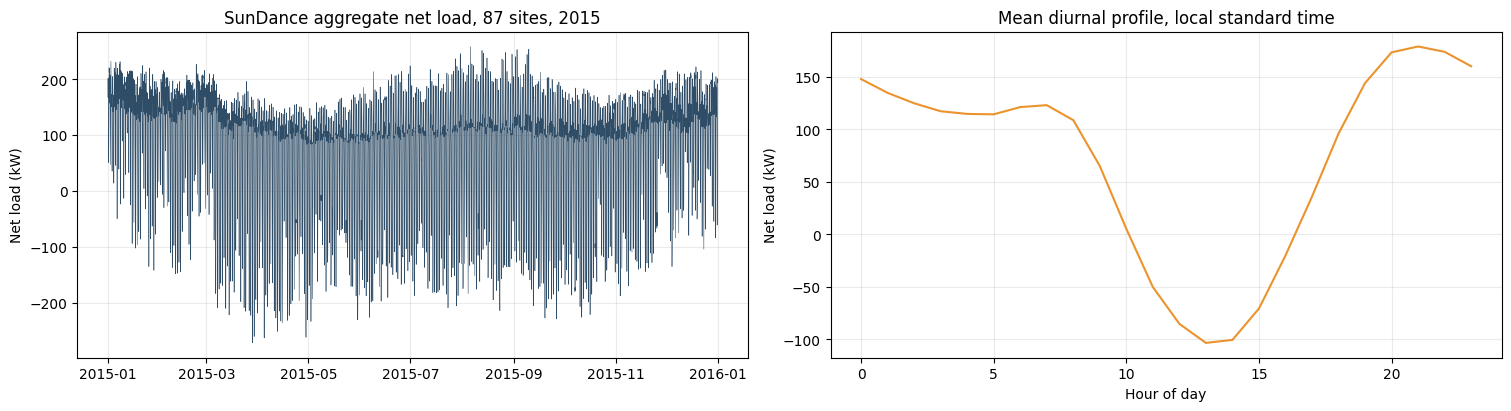

In [5]:
aligned = pd.DataFrame({
    site_id: standard_series[site_id].reindex(EXPECTED_INDEX).interpolate(method="time", limit=MAX_GAP_HOURS, limit_area="inside")
    for site_id in included_sites
})
if aligned.isna().any().any():
    raise AssertionError("Included sites still contain missing hours after interpolation.")

ds37 = pd.DataFrame({"datetime": EXPECTED_INDEX, "netload_kW": aligned.sum(axis=1).values})
ds37.to_csv(DS37_PATH, index=False)

print(f"Exported {DS37_PATH.name}: {ds37.shape[0]:,} rows from {len(included_sites)} sites")
print(f"Mean net load {ds37['netload_kW'].mean():.1f} kW, min {ds37['netload_kW'].min():.1f} kW, max {ds37['netload_kW'].max():.1f} kW")
display(ds37.head())

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
axes[0].plot(ds37["datetime"], ds37["netload_kW"], linewidth=0.4, color="#2F4D67")
axes[0].set_title(f"SunDance aggregate net load, {len(included_sites)} sites, 2015")
axes[0].set_ylabel("Net load (kW)")
diurnal = ds37.groupby(ds37["datetime"].dt.hour)["netload_kW"].mean()
axes[1].plot(diurnal.index, diurnal.values, color="#EB932C")
axes[1].set_title("Mean diurnal profile, local standard time")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Net load (kW)")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


## 6. Add site-mean weather for `ds38`

The release ships each site's nearest public weather station observations. For the included sites that have a weather file, temperature (°C), relative humidity (%) and wind speed (km/h) are averaged per hour across sites on the standard clock, then forward-filled over the few hours without any observation. The columns are renamed to the names used by the ASHD and ACAP-EDP datasets so the same model configuration applies.

In [6]:
weather_sites = [site_id for site_id in included_sites if site_id in site_weather]
stacked = pd.concat([site_weather[site_id].reindex(EXPECTED_INDEX) for site_id in weather_sites], keys=weather_sites, names=["site", "datetime"])
weather = stacked.groupby(level="datetime").mean().reindex(EXPECTED_INDEX)
weather = weather.rename(columns={"tempm": WEATHER_COLUMNS[0], "hum": WEATHER_COLUMNS[1], "wspdm": WEATHER_COLUMNS[2]})
hours_without_observation = int(weather.isna().any(axis=1).sum())
weather = weather.ffill().bfill()
if weather.isna().any().any():
    raise ValueError("Weather still contains missing values after forward fill.")

ds38 = ds37.merge(weather.reset_index(), on="datetime", how="left", validate="one_to_one")
ds38 = ds38[["datetime", "netload_kW", *WEATHER_COLUMNS]]
ds38.to_csv(DS38_PATH, index=False)

print(f"Weather averaged over {len(weather_sites)} of {len(included_sites)} included sites; {hours_without_observation} hours filled from the previous hour")
print(f"Exported {DS38_PATH.name}: {ds38.shape[0]:,} rows")
display(ds38.describe().round(2))


Weather averaged over 68 of 87 included sites; 0 hours filled from the previous hour
Exported ds38_sundance_hourly_with_weather.csv: 8,760 rows


,datetime,netload_kW,air_temperature_in_degrees_c,relative_humidity_in_percentage,wind_speed_in_km_h
count,8760,8760.00,8760.00,8760.00,8760.00
mean,2015-07-02 11:30:00,71.25,14.37,63.80,10.26
min,2015-01-01 00:00:00,-272.09,-5.87,26.64,1.53
25%,2015-04-02 05:45:00,6.11,8.26,52.37,7.57
50%,2015-07-02 11:30:00,108.50,14.67,65.61,9.79
75%,2015-10-01 17:15:00,145.70,20.16,75.66,12.58
max,2015-12-31 23:00:00,258.95,32.70,92.62,34.09
std,NaN,105.27,8.20,14.87,3.60


## 7. Final validation

Confirm row counts, hourly regularity, missing values, column order and the date range for both datasets, then copy them to the publication data folder.

In [7]:
expected_columns = {
    DS37_PATH.name: ["datetime", "netload_kW"],
    DS38_PATH.name: ["datetime", "netload_kW", *WEATHER_COLUMNS],
}

validation_rows = []
for path in [DS37_PATH, DS38_PATH]:
    dataset = pd.read_csv(path, parse_dates=["datetime"])
    if list(dataset.columns) != expected_columns[path.name]:
        raise AssertionError(f"Unexpected columns in {path.name}: {list(dataset.columns)}")
    if dataset.shape[0] != EXPECTED_ROWS:
        raise AssertionError(f"{path.name} expected {EXPECTED_ROWS:,} rows, found {dataset.shape[0]:,}")
    if dataset["datetime"].duplicated().any():
        raise AssertionError(f"{path.name} contains duplicate timestamps")
    if dataset.isna().any().any():
        raise AssertionError(f"{path.name} contains missing values")
    if dataset["datetime"].min() != START or dataset["datetime"].max() != END:
        raise AssertionError(f"{path.name} has an unexpected date range")
    freq_minutes = dataset["datetime"].diff().dropna().dt.total_seconds().unique() / 60
    if len(freq_minutes) != 1 or freq_minutes[0] != 60:
        raise AssertionError(f"{path.name} does not have regular hourly spacing")

    shutil.copyfile(path, PUBLICATION_DATA_DIR / path.name)
    validation_rows.append({
        "dataset": path.name,
        "rows": dataset.shape[0],
        "columns": ", ".join(dataset.columns),
        "start": dataset["datetime"].min(),
        "end": dataset["datetime"].max(),
        "missing_values": int(dataset.isna().sum().sum()),
    })

validation = pd.DataFrame(validation_rows)
display(validation)
print("All SunDance dataset exports passed validation and were copied to the publication data folder.")


,dataset,rows,columns,start,end,missing_values
0,ds37_sundance_hourly.csv,8760,"datetime, netload_kW",2015-01-01,2015-12-31 23:00:00,0
1,ds38_sundance_hourly_with_weather.csv,8760,"datetime, netload_kW, air_temperature_in_degre...",2015-01-01,2015-12-31 23:00:00,0


All SunDance dataset exports passed validation and were copied to the publication data folder.


## Conclusion

`ds37` and `ds38` hold one calendar year (2015) of hourly aggregate net load for the SunDance sites that passed the residential-scale and completeness checks, on a regular local standard-time index with no missing values. `ds38` adds the site-mean temperature, humidity and wind speed under the same column names as the Australian datasets, so the model comparison can run on it unchanged at the one-day horizon. The audit file records every site's inclusion decision.